In [220]:
import pandas as pd

In [221]:
#loads database
db = pd.read_excel ("Online Retail.xlsx")

In [222]:
#Shows 5 Records
print(db.head(5))

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [223]:
#Displays database info
print(db.info(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


In [224]:
#dataset dimensions
print(db.shape)

(541909, 8)


In [225]:
#count missing values
missing_v = db.isnull().sum()
print(missing_v)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [226]:
#percentage missing
missing_p = (missing_v / len(db)) * 100
print(missing_p)

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


In [227]:
#summary
missing_s = pd.DataFrame({
   "Missing Values": missing_v,
   "Missing Percenage": missing_p
 })

print(missing_s)

             Missing Values  Missing Percenage
InvoiceNo                 0           0.000000
StockCode                 0           0.000000
Description            1454           0.268311
Quantity                  0           0.000000
InvoiceDate               0           0.000000
UnitPrice                 0           0.000000
CustomerID           135080          24.926694
Country                   0           0.000000


In [228]:
#print negative quantities
print("Negative Quantities:", (db["Quantity"] < 0).sum())

Negative Quantities: 10624


In [229]:
#print 0 or less unit prices
print("Zero or Less Unit Prices:", (db["UnitPrice"] <= 0).sum())

Zero or Less Unit Prices: 2517


In [230]:
#print cancelled invoices
print("Cancelled Invoices:",(db["InvoiceNo"].str.startswith("C", na=False)).sum())

Cancelled Invoices: 9288


In [231]:
# Check how many negative quantity records
# belong to cancelled invoices
cancelled = db["InvoiceNo"].str.startswith("C", na=False)
negative = db["Quantity"] < 0

In [232]:
print("Negative quantities with cancelled invoices:", (negative & cancelled).sum())
print("Negative quantities without cancelled invoices:", (negative & ~cancelled).sum())

Negative quantities with cancelled invoices: 9288
Negative quantities without cancelled invoices: 1336


In [233]:
print("Cancelled INvoices with positive quantities:", ((cancelled & (db["Quantity"] > 0)).sum()))
print("Records with zero or negative prices:", (db["UnitPrice"] <= 0).sum())

Cancelled INvoices with positive quantities: 0
Records with zero or negative prices: 2517


In [234]:
#records not associated with cencellations
other_returns = db[(db["Quantity"] < 0) & (~cancelled)]
print(other_returns.head(10))

     InvoiceNo StockCode Description  Quantity         InvoiceDate  UnitPrice  \
2406    536589     21777         NaN       -10 2010-12-01 16:50:00        0.0   
4347    536764    84952C         NaN       -38 2010-12-02 14:42:00        0.0   
7188    536996     22712         NaN       -20 2010-12-03 15:30:00        0.0   
7189    536997     22028         NaN       -20 2010-12-03 15:30:00        0.0   
7190    536998     85067         NaN        -6 2010-12-03 15:30:00        0.0   
7192    537000     21414         NaN       -22 2010-12-03 15:32:00        0.0   
7193    537001     21653         NaN        -6 2010-12-03 15:33:00        0.0   
7195    537003     85126         NaN        -2 2010-12-03 15:33:00        0.0   
7196    537004     21814         NaN       -30 2010-12-03 15:34:00        0.0   
7197    537005     21692         NaN       -70 2010-12-03 15:35:00        0.0   

      CustomerID         Country  
2406         NaN  United Kingdom  
4347         NaN  United Kingdom  
718

In [235]:
print("Avg Unit Prices: ", other_returns["UnitPrice"].mean())

Avg Unit Prices:  0.0


In [236]:
print(other_returns["UnitPrice"].value_counts())

UnitPrice
0.0    1336
Name: count, dtype: int64


In [237]:
print("Missing Descriptions: ", other_returns["Description"].isnull().sum())
print("Missing Customer IDs: ", other_returns["CustomerID"].isnull().sum())

Missing Descriptions:  862
Missing Customer IDs:  1336


In [238]:
print(other_returns["StockCode"].value_counts().head(10))

StockCode
85175     5
21830     5
82494L    4
22719     4
85172     4
72802C    4
20966     3
22423     3
35954     3
85017A    3
Name: count, dtype: int64


In [239]:
#Number of records remaining excluding negative quantities, zero or negative unit prices and cancelled invoices
actual_sales = db[(db["Quantity"] > 0) & (db["UnitPrice"] > 0) & (~cancelled)].copy()

print("Original Records: ", len(db))
print("Valid Sales Records: ", len(actual_sales))
print("Excluded Records: ", len(db) - len(actual_sales))

Original Records:  541909
Valid Sales Records:  530104
Excluded Records:  11805


In [240]:
#Monthly Revenue
actual_sales["TotalPrice"] = (actual_sales["Quantity"] * actual_sales["UnitPrice"])
print(actual_sales["Quantity"].head(), actual_sales["UnitPrice"].head(), actual_sales["TotalPrice"].head())

0    6
1    6
2    8
3    6
4    6
Name: Quantity, dtype: int64 0    2.55
1    3.39
2    2.75
3    3.39
4    3.39
Name: UnitPrice, dtype: float64 0    15.30
1    20.34
2    22.00
3    20.34
4    20.34
Name: TotalPrice, dtype: float64


In [241]:
#sales grouped by month
monthly_revenue = actual_sales.groupby(actual_sales["InvoiceDate"].dt.to_period("M"))["TotalPrice"].sum()
print(monthly_revenue)

InvoiceDate
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: TotalPrice, dtype: float64


In [242]:
import matplotlib.pyplot as plt

In [243]:
#monthly periods to timestamps
monthly_revenue.index = monthly_revenue.index.to_timestamp()

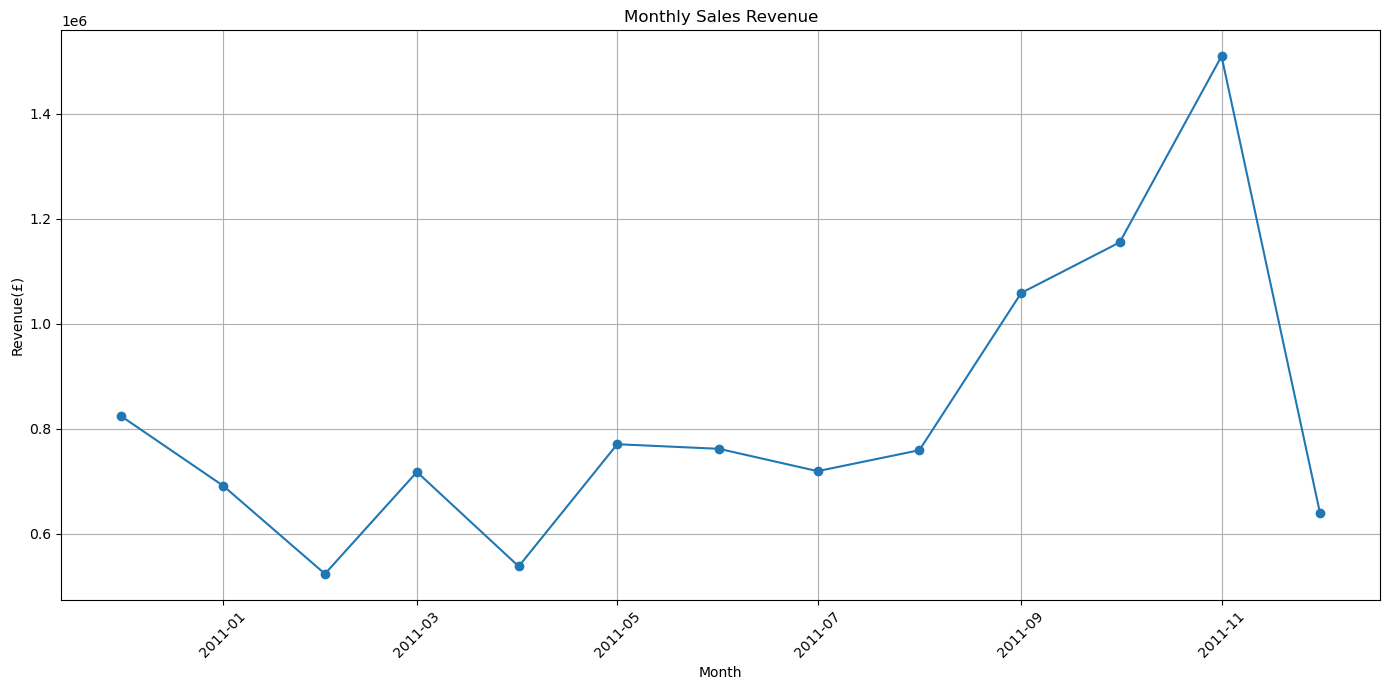

In [244]:
plt.figure(figsize=(14, 7))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o")

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue(£)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [245]:
#finding highest and lowest revenue months
highest_m = monthly_revenue.idxmax()
highest_r = monthly_revenue.max()

print("Highest revenue month:", highest_m.strftime("%B %Y"))
print("Highest revenue:", round(highest_r, 2), "GBP")

Highest revenue month: November 2011
Highest revenue: 1509496.33 GBP


In [246]:
lowest_m = monthly_revenue.idxmin()
lowest_r = monthly_revenue.min()

print("Lowest revenue month:", lowest_m.strftime("%B %Y"))
print("Lowest revenue:", round(lowest_r, 2), "GBP")

Lowest revenue month: February 2011
Lowest revenue: 523631.89 GBP


In [247]:
#Best Selling Products
top_products = actual_sales.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48474
WHITE HANGING HEART T-LIGHT HOLDER    37891
POPCORN HOLDER                        36761
ASSORTED COLOUR BIRD ORNAMENT         36461
PACK OF 72 RETROSPOT CAKE CASES       36419
RABBIT NIGHT LIGHT                    30788
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


In [248]:
#Top products by total revenue
highest_revenue_products = actual_sales.groupby("Description")["TotalPrice"].sum().sort_values(ascending=False).head(10)
print(highest_revenue_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: TotalPrice, dtype: float64


In [249]:
#Revenue by country
country_revenue = actual_sales.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False).head(10)
print(country_revenue)

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: TotalPrice, dtype: float64


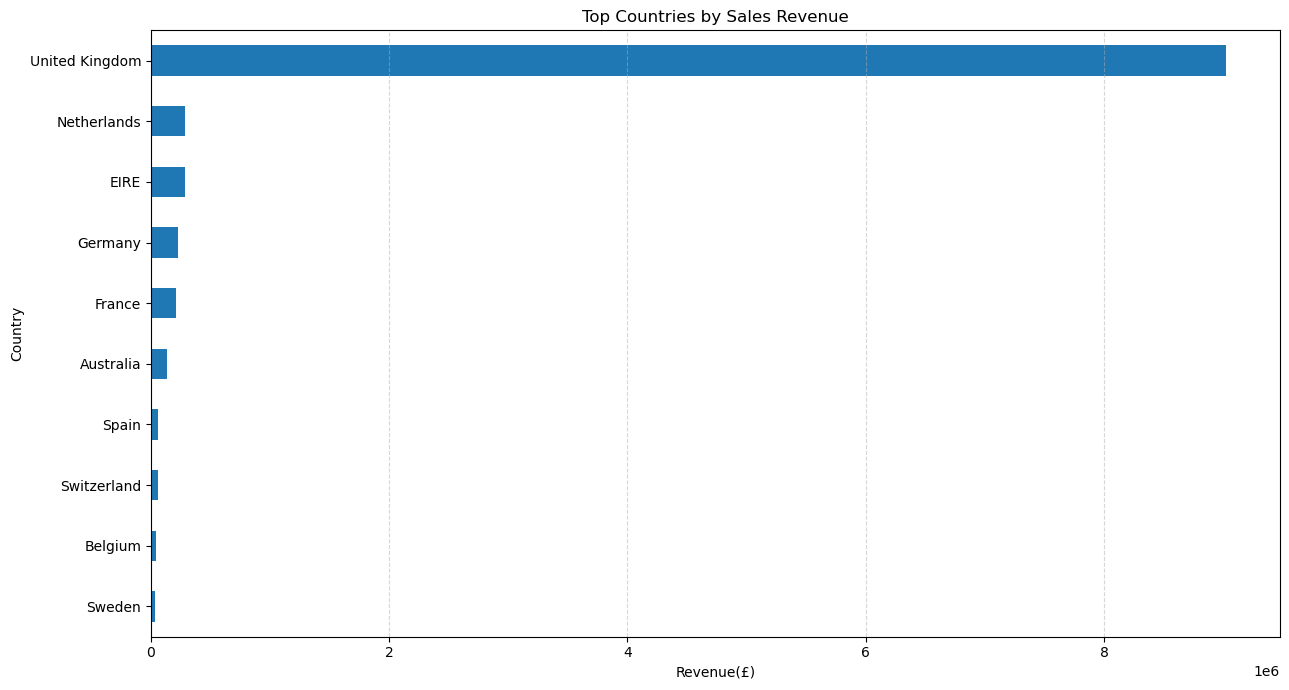

In [250]:
plt.figure(figsize=(13, 7))
country_revenue.sort_values().plot(kind ="barh", title="Top Countries by Sales Revenue")

plt.xlabel("Revenue(£)")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [251]:
#Customers by Revenue
customer_revenue = actual_sales.dropna(subset=["CustomerID"]).groupby("CustomerID")["TotalPrice"].sum().sort_values(ascending=False).head(10)
print(customer_revenue)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: TotalPrice, dtype: float64


In [252]:
# Number of unique purchases per customer
customer_purchases = actual_sales.dropna(subset=["CustomerID"]).groupby("CustomerID")["InvoiceNo"].nunique().sort_values(ascending=False).head(10)
print(customer_purchases)

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


In [253]:
#Average Order Value
avg_order_value = actual_sales.dropna(subset=["CustomerID"]).groupby("CustomerID").apply(lambda x: x.groupby("InvoiceNo")["TotalPrice"].sum().mean(), include_groups=False).sort_values(ascending=False).head(10)
print(avg_order_value)

CustomerID
16446.0    84236.250000
12346.0    77183.600000
15749.0    14844.766667
15098.0    13305.500000
12357.0     6207.670000
12415.0     5948.310952
12590.0     4932.130000
12688.0     4873.810000
12752.0     4366.780000
18102.0     4327.621667
dtype: float64


In [254]:
#counting unique customers
u_customers = actual_sales["CustomerID"].nunique()
print(u_customers)

4338


In [255]:
#avg order value
total_revenue = actual_sales["TotalPrice"].sum()
total_orders = actual_sales["InvoiceNo"].nunique()
overall_avg_order = total_revenue / total_orders
print("Overall Average Order Value: ", round(overall_avg_order, 2), "GBP")

Overall Average Order Value:  534.4 GBP


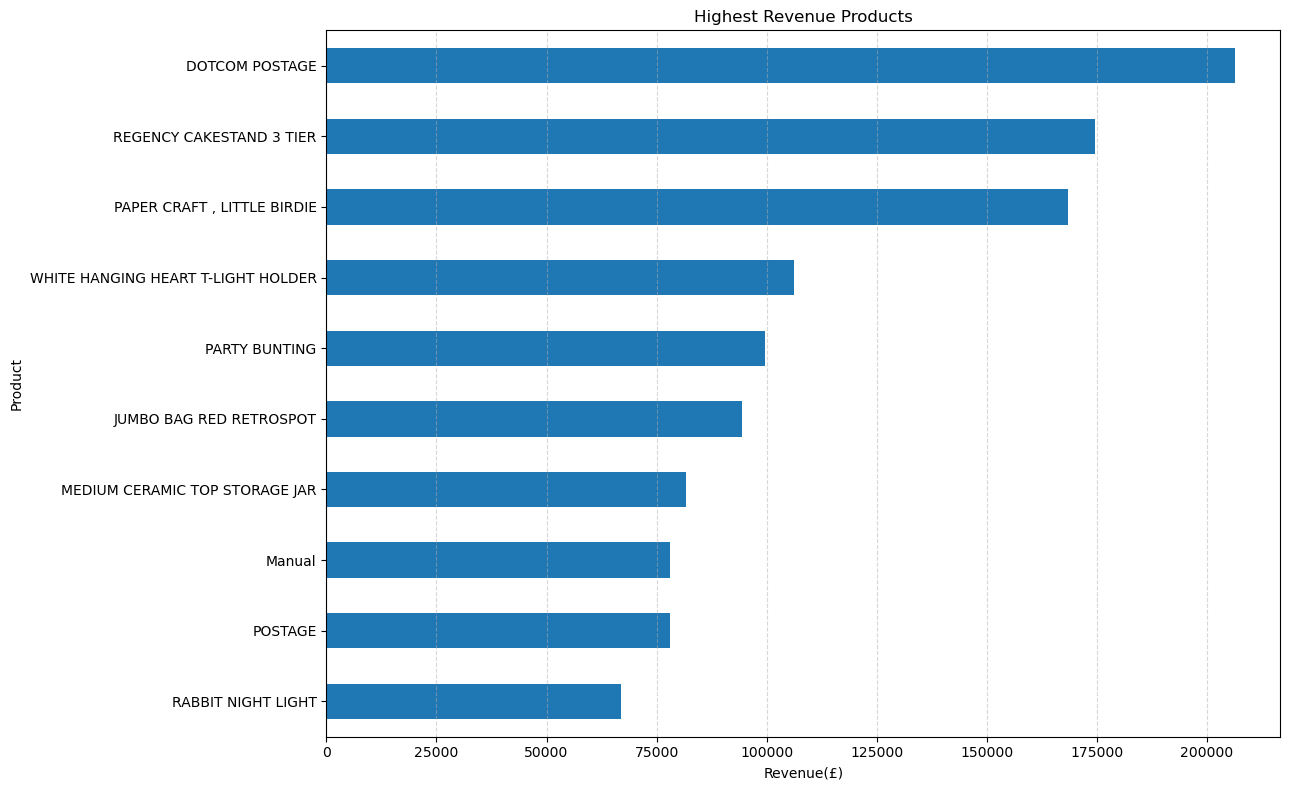

In [256]:
plt.figure(figsize=(13, 8))

highest_revenue_products.sort_values().plot(kind="barh", title="Highest Revenue Products")
plt.xlabel("Revenue(£)")
plt.ylabel("Product")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

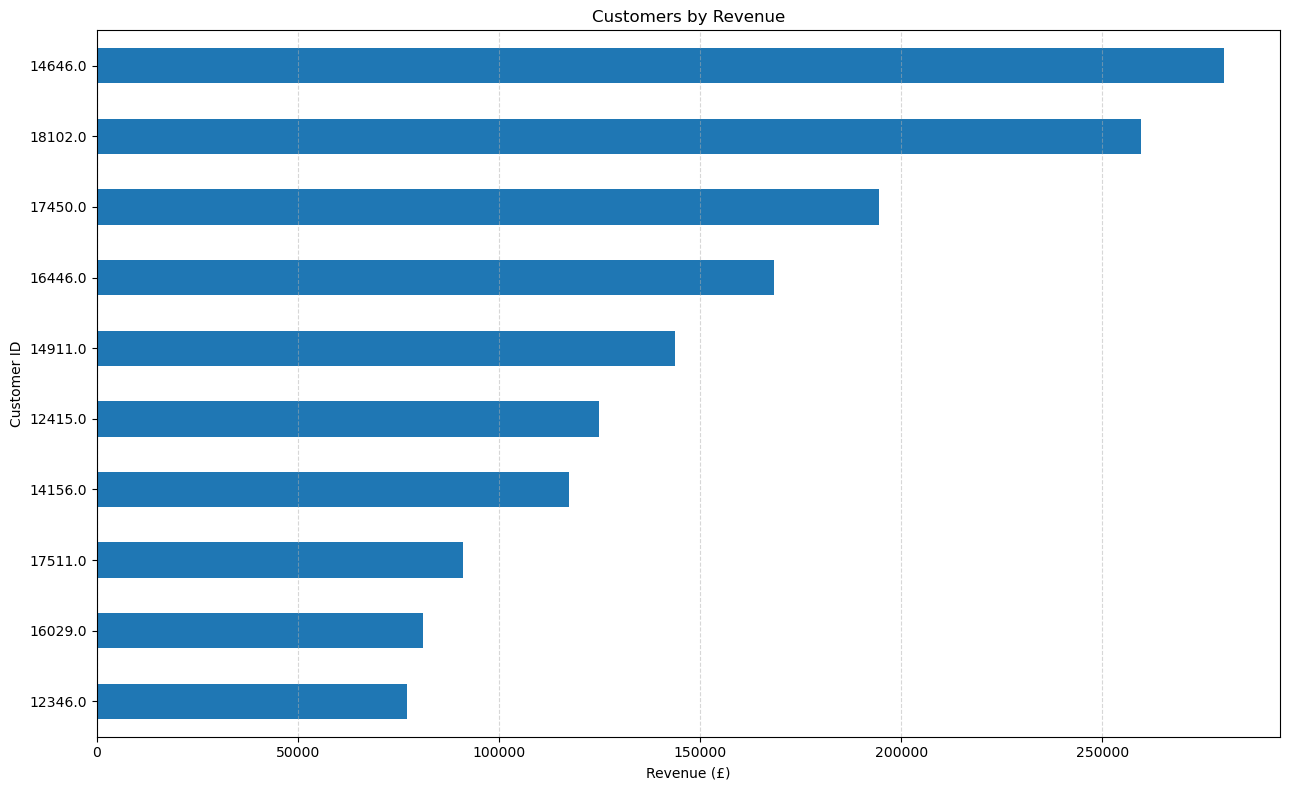

In [257]:
plt.figure(figsize=(13, 8))
customer_revenue.sort_values().plot(kind="barh",title="Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [258]:
#Function for displaying top products by revenue
def get_top_products_by_revenue(data):
    top_products = data.groupby("Description")["TotalPrice"].sum().sort_values(ascending=False).head(10)

    return top_products

In [259]:
highest_revenue_products = get_top_products_by_revenue(actual_sales)

print(highest_revenue_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: TotalPrice, dtype: float64


In [260]:
#A function for top customers by revenue
def get_top_customers_by_revenue(data):
    top_customers = data.dropna(subset=["CustomerID"]).groupby("CustomerID")["TotalPrice"].sum().sort_values(ascending=False).head(10)

    return top_customers

In [261]:
top_customer_revenues = get_top_customer_by_revenue(actual_sales)

print(top_customer_revenues)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: TotalPrice, dtype: float64


In [262]:
#A function for monthly revenue 
def get_monthly_revenue(data):
    monthly_revenue = data.groupby(data["InvoiceDate"].dt.to_period("M"))["TotalPrice"].sum()

    return monthly_revenue

In [263]:
top_monthly_revenues = get_monthly_revenue(actual_sales)

print(top_monthly_revenues)

InvoiceDate
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: TotalPrice, dtype: float64


In [264]:
def get_revenue_by_country(data):
    country_revenue = data.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False).head(10)
    
    return country_revenue

In [265]:
revenue_by_country = get_revenue_by_country(actual_sales)

print(revenue_by_country)

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: TotalPrice, dtype: float64


In [266]:
def get_top_products_by_quantity(data):
    top_products = data.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)

    return top_products

In [267]:
top_products_by_quantity = get_top_products_by_quantity(actual_sales)

print(top_products_by_quantity)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48474
WHITE HANGING HEART T-LIGHT HOLDER    37891
POPCORN HOLDER                        36761
ASSORTED COLOUR BIRD ORNAMENT         36461
PACK OF 72 RETROSPOT CAKE CASES       36419
RABBIT NIGHT LIGHT                    30788
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


In [268]:
def get_top_customers_by_orders(data):
    top_customers_by_orders = (data.dropna(subset=["CustomerID"]).groupby("CustomerID")["InvoiceNo"].nunique().sort_values(ascending=False).head(10)
    )

    return top_customers_by_orders

In [269]:
top_customers_by_quantity = get_top_customers_by_orders(actual_sales)

print(top_customers_by_quantity)

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


In [270]:
def get_average_order_value(data):
    avg_order_value = data.dropna(subset=["CustomerID"]).groupby("CustomerID").apply(lambda x: x.groupby("InvoiceNo")["TotalPrice"].sum().mean(), include_groups=False).sort_values(ascending=False).head(10)

    return avg_order_value

In [271]:
avg_order_value = get_average_order_value(actual_sales)

print(avg_order_value)

CustomerID
16446.0    84236.250000
12346.0    77183.600000
15749.0    14844.766667
15098.0    13305.500000
12357.0     6207.670000
12415.0     5948.310952
12590.0     4932.130000
12688.0     4873.810000
12752.0     4366.780000
18102.0     4327.621667
dtype: float64


In [272]:
print("\n--- TOP PRODUCTS BY REVENUE ---")
print(get_top_products_by_revenue(actual_sales))

print("\n--- TOP CUSTOMERS BY REVENUE ---")
print(get_top_customer_by_revenue(actual_sales))

print("\n--- MONTHLY REVENUE ---")
print(get_monthly_revenue(actual_sales))

print("\n--- REVENUE BY COUNTRY ---")
print(get_revenue_by_country(actual_sales))

print("\n--- TOP PRODUCTS BY QUANTITY ---")
print(get_top_products_by_quantity(actual_sales))

print("\n--- TOP CUSTOMERS BY ORDERS ---")
print(get_top_customers_by_orders(actual_sales))

print("\n--- TOP CUSTOMERS BY AVERAGE ORDER VALUE ---")
print(get_average_order_value(actual_sales))


--- TOP PRODUCTS BY REVENUE ---
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: TotalPrice, dtype: float64

--- TOP CUSTOMERS BY REVENUE ---
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: TotalPrice, dtype: float64

--- MONTHLY REVENUE ---
InvoiceDate
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
20

In [273]:
def display_menu():
    print("\n===== ONLINE RETAIL DATA ANALYSIS =====")
    print("1. Top products by revenue")
    print("2. Top customers by revenue")
    print("3. Monthly revenue")
    print("4. Revenue by country")
    print("5. Top products by quantity")
    print("6. Top customers by orders")
    print("7. Average order value by customer")
    print("0. Exit")

In [274]:
display_menu()


===== ONLINE RETAIL DATA ANALYSIS =====
1. Top products by revenue
2. Top customers by revenue
3. Monthly revenue
4. Revenue by country
5. Top products by quantity
6. Top customers by orders
7. Average order value by customer
0. Exit


In [278]:
choice = input("Enter your choice (0-7): ")

print("You selected:", choice)

Enter your choice (0-7):  2


You selected: 2


In [189]:
choice = int(input("Enter your choice (0-7): "))

if choice == 1:
    print(get_top_products_by_revenue(actual_sales))

elif choice == 2:
    print(get_top_customer_by_revenue(actual_sales))

elif choice == 3:
    print(get_monthly_revenue(actual_sales))

elif choice == 4:
    print(get_revenue_by_country(actual_sales))

elif choice == 5:
    print(get_top_products_by_quantity(actual_sales))

elif choice == 6:
    print(get_top_customers_by_orders(actual_sales))

elif choice == 7:
    print(get_average_order_value(actual_sales))

elif choice == 0:
    print("Exiting the program. Goodbye!")

else:
    print("Invalid choice. Please enter a number between 0 and 7.")

Enter your choice (0-7):  1


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: TotalPrice, dtype: float64


In [279]:
def display_results(title, results):
    print("\n" + "=" * 50)
    print(title)
    print("=" * 50)
    print(results.to_string())

In [300]:
def plot_monthly_revenue(data):
    monthly_revenue = get_monthly_revenue(data)

    monthly_revenue.index = monthly_revenue.index.to_timestamp()

    plt.figure(figsize=(12, 6))
    plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker="o")

    plt.title("Monthly Sales Revenue")
    plt.xlabel("Month")
    plt.ylabel("Revenue (£)")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()

    os.makedirs("charts", exist_ok=True)
    plt.savefig("charts/monthly_revenue.png", dpi=300, bbox_inches="tight")

    plt.show()

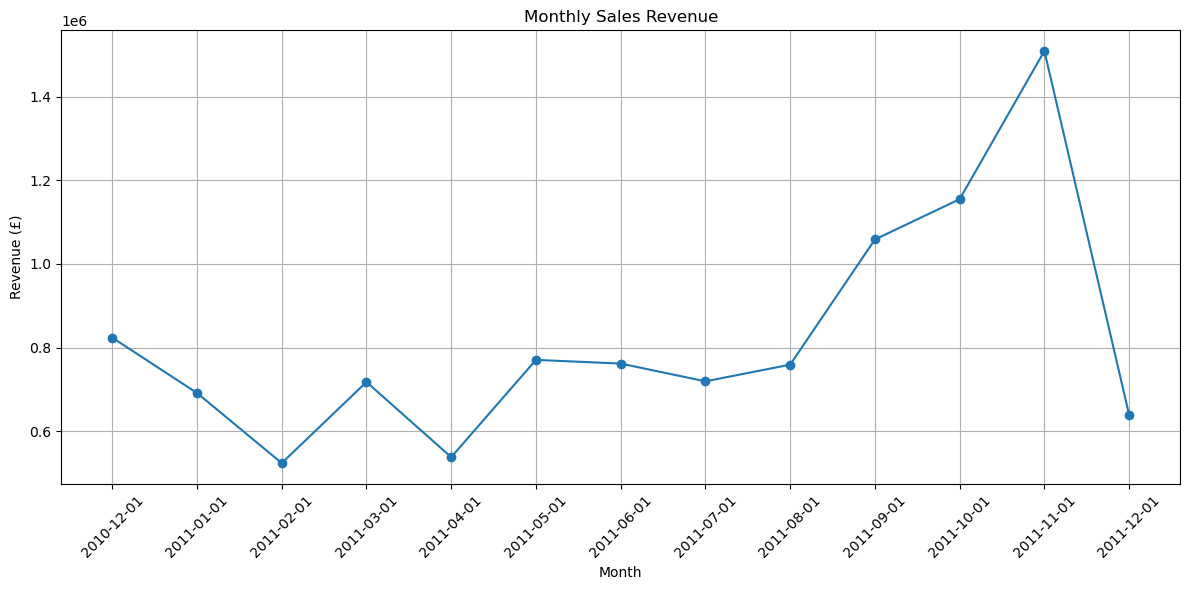

In [301]:
plot_monthly_revenue(actual_sales)

In [302]:
def plot_revenue_by_country(data):
    revenue_by_country = get_revenue_by_country(data)

    plt.figure(figsize=(13, 7))
    revenue_by_country.sort_values().plot(
        kind="barh",
        title="Top Countries by Sales Revenue"
    )

    plt.xlabel("Revenue (£)")
    plt.ylabel("Country")
    plt.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()

    os.makedirs("charts", exist_ok=True)
    plt.savefig("charts/Top Countries by Sales Revenue.png", dpi=300, bbox_inches="tight")
    
    plt.show()

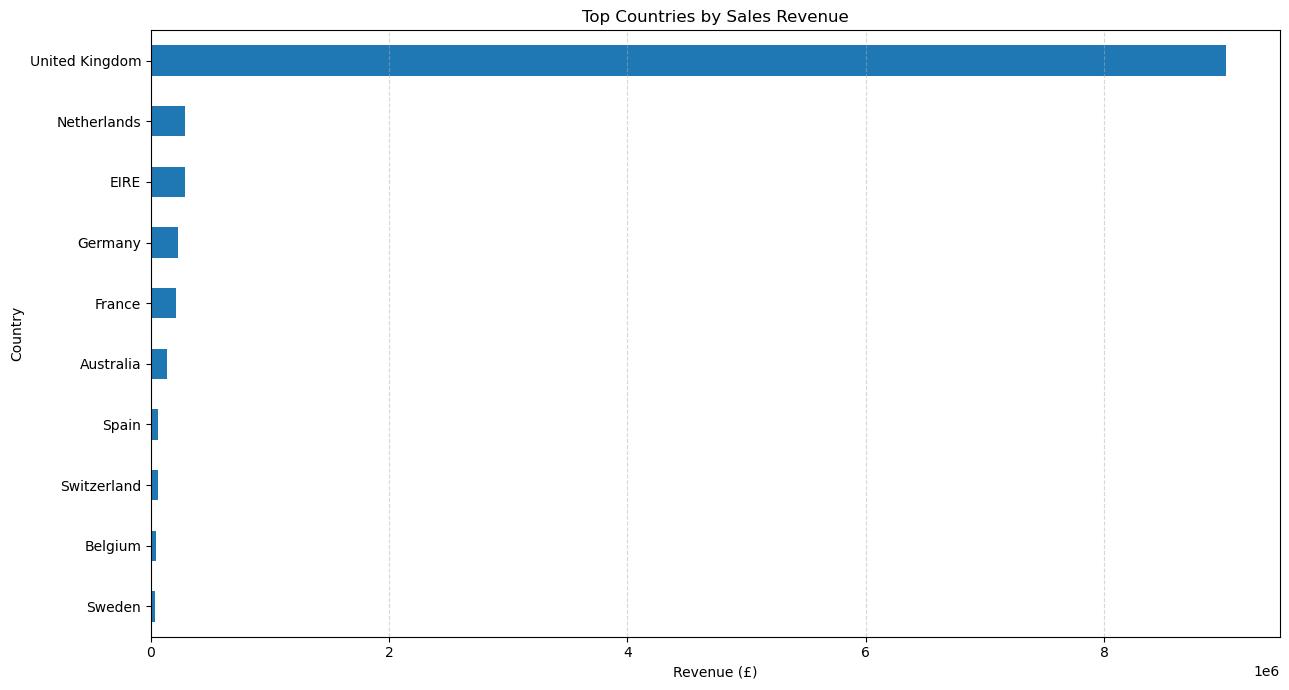

In [303]:
plot_revenue_by_country(actual_sales)

In [304]:
def plot_top_products_by_revenue(data):
    top_products_by_revenue = get_top_products_by_revenue(data)

    plt.figure(figsize=(13, 7))
    top_products_by_revenue.sort_values().plot(
        kind="barh",
        title="Top Products by Sales Revenue"
    )

    plt.xlabel("Revenue (£)")
    plt.ylabel("Product")
    plt.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()

    os.makedirs("charts", exist_ok=True)
    plt.savefig("charts/Top Products by Sales Revenue", dpi=300, bbox_inches="tight")
    
    plt.show()

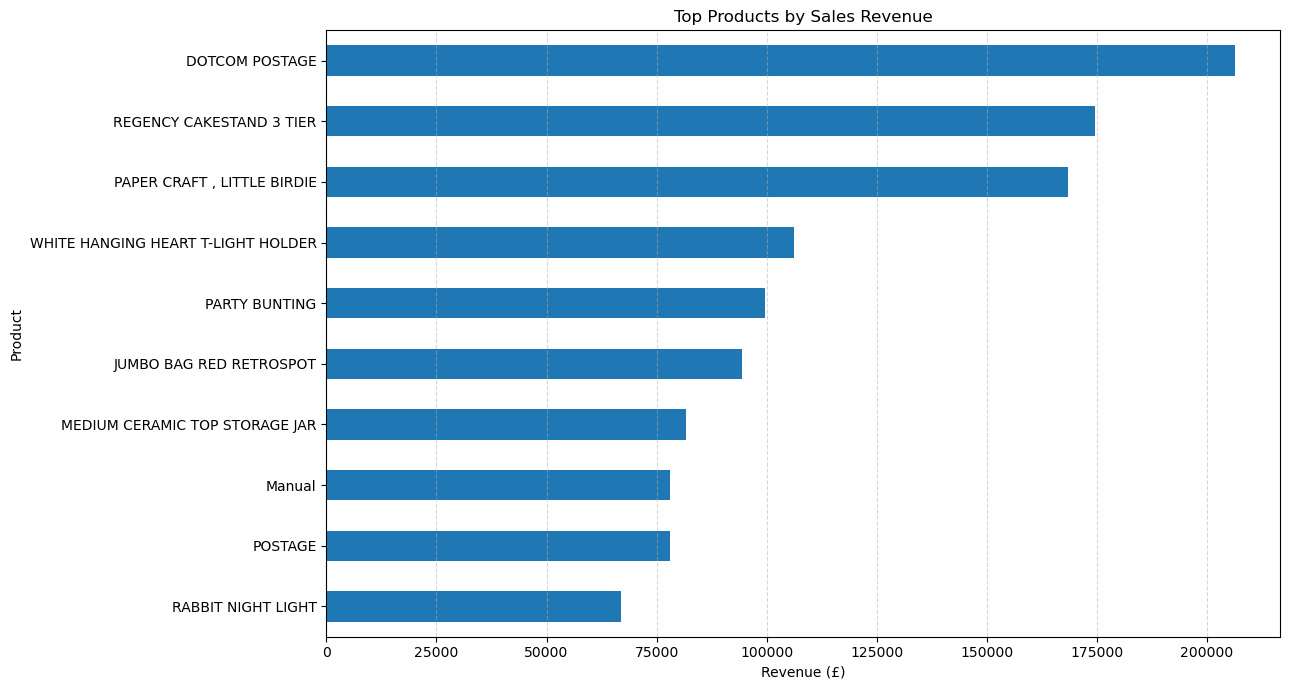

In [305]:
plot_top_products_by_revenue(actual_sales)

In [306]:
def plot_top_customers_by_revenue(data):

    top_customers_by_revenue = get_top_customer_by_revenue(data)

    plt.figure(figsize=(13, 7))
    top_customers_by_revenue.sort_values().plot(
        kind="barh",
        title="Top Customers by Sales Revenue"
    )

    plt.xlabel("Revenue (£)")
    plt.ylabel("CustomerID")
    plt.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()

    os.makedirs("charts", exist_ok=True)
    plt.savefig("charts/Top Customers by Sales Revenue", dpi=300, bbox_inches="tight")
    
    plt.show()

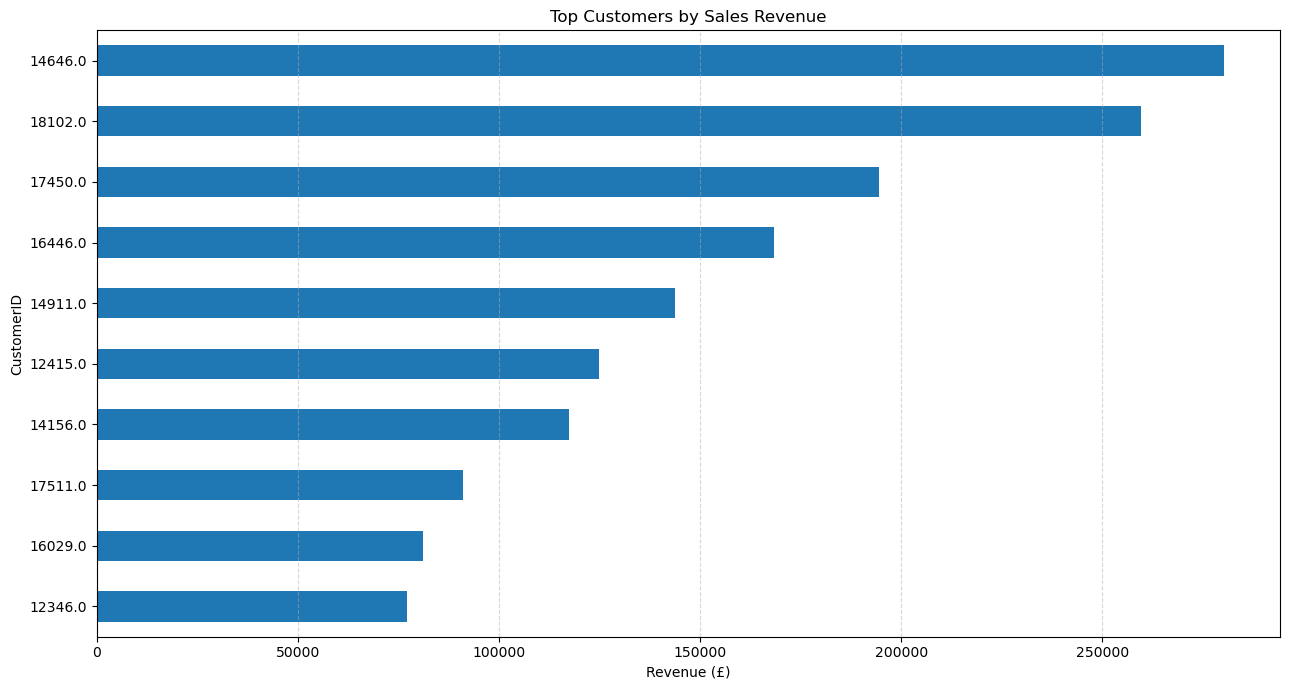

In [307]:
plot_top_customers_by_revenue(actual_sales)

In [294]:
import os

In [295]:
def export_results(results, filename):
    os.makedirs("exports", exist_ok=True)

    filepath = os.path.join("exports", filename)

    results.to_csv(filepath, header=["Value"])

    print(f"\nResults successfully exported to: {filepath}")

In [297]:
# Display analysis results
def display_results(title, results):
    print("\n" + "=" * 50)
    print(title)
    print("=" * 50)
    print(results.to_string())


# Display the menu
def display_menu():
    print("\n===== ONLINE RETAIL DATA ANALYSIS =====")
    print("1. Top products by revenue")
    print("2. Top customers by revenue")
    print("3. Monthly revenue")
    print("4. Revenue by country")
    print("5. Top products by quantity")
    print("6. Top customers by orders")
    print("7. Average order value by customer")
    print("8. Monthly revenue chart")
    print("9. Revenue by country chart")
    print("10. Top products by revenue chart")
    print("11. Top customers by revenue chart")
    print("12. Export top products by revenue")
    print("13. Export top customers by revenue")
    print("14. Export monthly revenue")
    print("15. Export revenue by country")
    print("0. Exit")

# Main program
while True:
    display_menu()

    try:
      choice = int(input("\nEnter your choice (0-15): "))

    except ValueError:
        print("Invalid choice. Please enter a number between 0 and 15.")
        continue

    if choice == 1:
        display_results(
            "TOP PRODUCTS BY REVENUE",
            get_top_products_by_revenue(actual_sales)
        )

    elif choice == 2:
        display_results(
            "TOP CUSTOMERS BY REVENUE",
            get_top_customer_by_revenue(actual_sales)
        )

    elif choice == 3:
        display_results(
            "MONTHLY REVENUE",
            get_monthly_revenue(actual_sales)
        )

    elif choice == 4:
        display_results(
            "REVENUE BY COUNTRY",
            get_revenue_by_country(actual_sales)
        )

    elif choice == 5:
        display_results(
            "TOP PRODUCTS BY QUANTITY",
            get_top_products_by_quantity(actual_sales)
        )

    elif choice == 6:
        display_results(
            "TOP CUSTOMERS BY NUMBER OF ORDERS",
            get_top_customers_by_orders(actual_sales)
        )

    elif choice == 7:
        display_results(
            "TOP CUSTOMERS BY AVERAGE ORDER VALUE",
            get_average_order_value(actual_sales)
        )

    elif choice == 8:
        plot_monthly_revenue(actual_sales)

    elif choice == 9:
        plot_revenue_by_country(actual_sales)

    elif choice == 10:
        plot_top_products_by_revenue(actual_sales)

    elif choice == 11:
        plot_top_customers_by_revenue(actual_sales)

    elif choice == 12:
        export_results(
            get_top_products_by_revenue(actual_sales),
            "top_products_by_revenue.csv"
    )

    elif choice == 13:
        export_results(
            get_top_customer_by_revenue(actual_sales),
            "top_customers_by_revenue.csv"
    )

    elif choice == 14:
        export_results(
            get_monthly_revenue(actual_sales),
            "monthly_revenue.csv"
    )

    elif choice == 15:
        export_results(
            get_revenue_by_country(actual_sales),
            "revenue_by_country.csv"
    )
    
    elif choice == 0:
        print("\nExiting the program. Goodbye!")
        break

    else:
        print("Invalid choice. Please enter a number between 0 and 11.")





===== ONLINE RETAIL DATA ANALYSIS =====
1. Top products by revenue
2. Top customers by revenue
3. Monthly revenue
4. Revenue by country
5. Top products by quantity
6. Top customers by orders
7. Average order value by customer
8. Monthly revenue chart
9. Revenue by country chart
10. Top products by revenue chart
11. Top customers by revenue chart
12. Export top products by revenue
13. Export top customers by revenue
14. Export monthly revenue
15. Export revenue by country
0. Exit



Enter your choice (0-15):  15



Results successfully exported to: exports\revenue_by_country.csv

===== ONLINE RETAIL DATA ANALYSIS =====
1. Top products by revenue
2. Top customers by revenue
3. Monthly revenue
4. Revenue by country
5. Top products by quantity
6. Top customers by orders
7. Average order value by customer
8. Monthly revenue chart
9. Revenue by country chart
10. Top products by revenue chart
11. Top customers by revenue chart
12. Export top products by revenue
13. Export top customers by revenue
14. Export monthly revenue
15. Export revenue by country
0. Exit



Enter your choice (0-15):  0



Exiting the program. Goodbye!
